# Binary Classification with Keras

Keras is a powerful and easy-to-use deep learning library that allows you to build and train neural networks for various tasks, including binary classification. In this guide, we will walk through the steps to create a binary classification model using Keras.


## Requirements

1. Load the Breast Cancer dataset from scikit-learn.

2. Split the dataset into training and test sets.

3. Normalize the input features.

4. Build a neural network for binary classification using Keras.

5. Train the model and use validation data.

6. Plot training and validation loss and accuracy.

7. Evaluate the model using Confusion Matrix and Classification Report.


In [ ]:
# Import libraries
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

## Step 1: Load Dataset

Load the Breast Cancer dataset and extract input features X and labels y.


In [ ]:
# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target

print("Input shape:", X.shape)
print("Output shape:", y.shape)

Input shape: (569, 30)
Output shape: (569,)


## Step 2: Train-Test Split and Normalization

Split the dataset into training and test sets.
Apply feature scaling using StandardScaler.


In [ ]:
# Split data and normalize features
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Step 3: Build Neural Network Model

Build a neural network for binary classification.
Use Sigmoid activation in the output layer.


In [ ]:
# Sequential model
model = Sequential()

# Add hidden layers
model.add(Dense(32, input_dim=X_train.shape[1], activation='relu'))

# Add output layer with sigmoid activation
model.add(Dense(1, activation='sigmoid'))

# Compile the model
model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Step 4: Train the Model

Train the model using training data.
Use validation_split to monitor overfitting.


In [ ]:
# Train the model
history = model.fit(X_train, y_train, epochs=50, batch_size=16, validation_split=0.1, verbose=1)

Epoch 1/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - accuracy: 0.7213 - loss: 0.5870 - val_accuracy: 0.8696 - val_loss: 0.3704
Epoch 2/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9144 - loss: 0.3312 - val_accuracy: 0.9130 - val_loss: 0.2524
Epoch 3/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9389 - loss: 0.2372 - val_accuracy: 0.9348 - val_loss: 0.2032
Epoch 4/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9511 - loss: 0.1887 - val_accuracy: 0.9348 - val_loss: 0.1753
Epoch 5/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9535 - loss: 0.1589 - val_accuracy: 0.9130 - val_loss: 0.1555
Epoch 6/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9584 - loss: 0.1386 - val_accuracy: 0.9130 - val_loss: 0.1424
Epoch 7/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9633 - loss: 0.1232 - val_accuracy: 0.9130 - val_loss: 0.1315
Epoch 8/50
26/26 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9731 - loss: 0.1110 - val_accuracy: 0.9783 - val_loss

## Step 5: Visualization

Plot training and validation loss.
Plot training and validation accuracy.


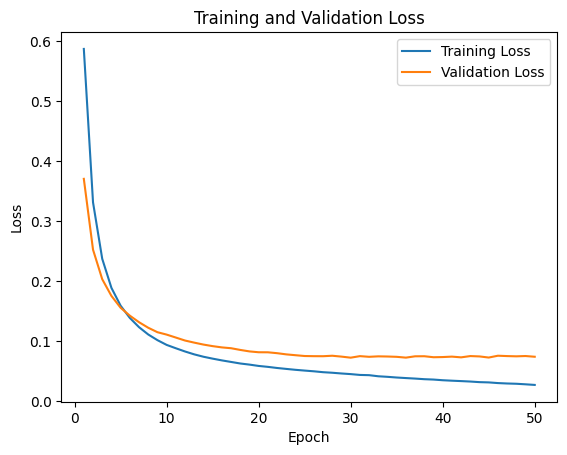

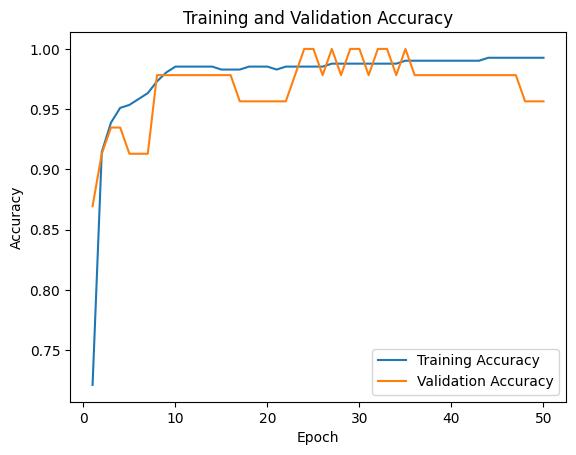

In [ ]:
# Plot loss and accuracy curves
loss = history.history['loss']
val_loss = history.history['val_loss']
accuracy = history.history['accuracy']
val_accuracy = history.history['val_accuracy']

epochs = range(1, len(loss) + 1)

# Loss
plt.figure()
plt.plot(epochs, loss, label='Training Loss')
plt.plot(epochs, val_loss, label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

# Accuracy
plt.figure()
plt.plot(epochs, accuracy, label='Training Accuracy')
plt.plot(epochs, val_accuracy, label='Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

## Step 6: Model Evaluation

Evaluate the model on the test set.
Compute Confusion Matrix and Classification Report.


4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


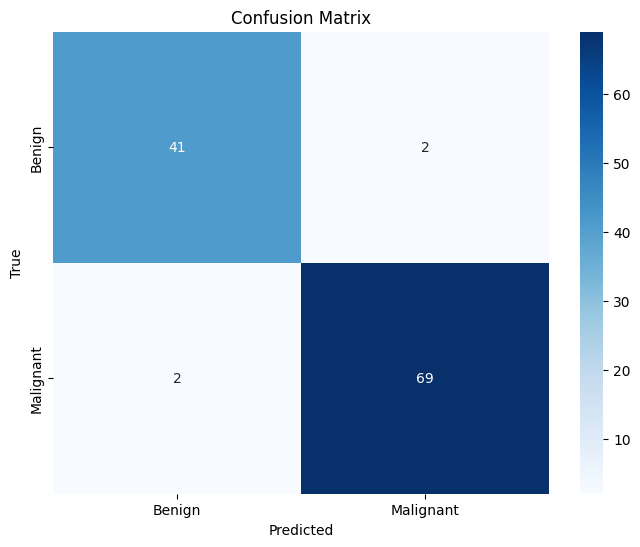

              precision    recall  f1-score   support

           0       0.95      0.95      0.95        43
           1       0.97      0.97      0.97        71

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



In [ ]:
# Predict on test data
y_pred = model.predict(X_test)
y_pred = (y_pred > 0.5).astype(int)

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

# Plot Confusion Matrix as heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()

# Print classification report
print(classification_report(y_test, y_pred))

# Key Observations

1. Sigmoid is used in the output layer for binary classification because it returns a single value p between 0 and 1, which represents the probability of the sample belongs to the positive class. Then we take (1 - p) to get the probability of the sample belongs to the negative class. The concept is built for binary classification problem which involves 2 labels (one is positive and the other is negative).

2. If the learning rate is too large. The model might shift the optimal value early. In Deep Learning, this means the optimizer makes excessively large updates to the weights, overshooting the minimum of the loss function.

3. Batch Size refers to the number of samples that the model will learn such that it updates the weight. This means the model processes a small subset of the training data (called a 'mini-batch'), calculates the error (loss), and adjusts its internal parameters (weights and biases) based on that subset before moving on t0 the next set of samples.

4. Epochs refer to the number of complete passes through the entire training dataset. In other words, one epoch means that every sample in the training dataset has had an opportunity to update the model's weights once.